<a href="https://colab.research.google.com/github/yang200212/MSSP-6070/blob/main/Modules/Week_8/PARTICIPATION_ACTIVITY_Week_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import userdata
import os
import subprocess
from pathlib import Path

owner = "yang200212" # Replace with the GitHub repository owner
repository = "MSSP-6070" # Replace with the GitHub repository name
repo_url = f'https://github.com/{owner}/{repository}.git'
repo_path = Path('/content') / repository

# Clone the repository
import subprocess
subprocess.run(['git', 'clone', repo_url])

# Navigate into the cloned repository directory (optional, but often useful)
os.chdir(repository)
print("Changed directory to: {os.getcwd()}")

Changed directory to: {os.getcwd()}


In [2]:
import subprocess

subprocess.run(
    ['git', '-C', str(repo_path), 'pull', 'origin', 'main'],
    check=True
)

CompletedProcess(args=['git', '-C', '/content/MSSP-6070', 'pull', 'origin', 'main'], returncode=0)

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Define dataset path
DATA_PATH = repo_path / 'Modules' / 'Week_8' / 'InternetSales.csv'

# Check whether the file exists
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Data file not found: {DATA_PATH}"
    )

# Load the CSV dataset
sales = pd.read_csv(DATA_PATH, encoding='cp1252')

# Confirm successful loading
print("Data loaded successfully!")
print("Data shape:", sales.shape)
display(sales.head())

Data loaded successfully!
Data shape: (60398, 60)


/tmp/ipykernel_761/3356124460.py:15: DtypeWarning: Columns (14) have mixed types. Specify dtype option on import or set low_memory=False.
  sales = pd.read_csv(DATA_PATH, encoding='cp1252')


,ID,CustomerKey,GeographyKey,City,CountryRegionCode,EnglishCountryRegionName,CustomerAlternateKey,Title,FirstName,MiddleName,...,ProductStandardCost,TotalProductCost,SalesAmount,TaxAmt,Freight,CarrierTrackingNumber,CustomerPONumber,OrderDate,DueDate,ShipDate
0,0,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1912.1544,1912.1544,3399.99,271.9992,84.9998,NaN,NaN,1/19/2011,1/31/2011,1/26/2011
1,1,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1265.6195,1265.6195,2319.99,185.5992,57.9998,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
2,2,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,8.2205,8.2205,21.98,1.7584,0.5495,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
3,3,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1481.9379,1481.9379,2384.07,190.7256,59.6018,NaN,NaN,5/3/2013,5/15/2013,5/10/2013
4,4,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,10.8423,10.8423,28.99,2.3192,0.7248,NaN,NaN,5/3/2013,5/15/2013,5/10/2013


In [12]:
sales['OrderDate'] = pd.to_datetime(sales['OrderDate'])

In [13]:
# create an internet sales forecast for the next five years

# calculate annual sales
annual_sales = sales.groupby(sales['OrderDate'].dt.year)['SalesAmount'].sum()
# since 2010 and 2014 only have sales record for one season, limit sales data to 2011-2013
annual_sales = annual_sales.loc[2011:2013]

# fit linear trend model
years = annual_sales.index.to_numpy()
sales1 = annual_sales.to_numpy()

slope, intercept = np.polyfit(years, sales1, 1)

# forecast for next five years
next_5years = np.arange(2014, 2019)
forecast_sales = slope * next_5years + intercept
forecast = pd.DataFrame({'Year': next_5years, 'Forecasted Sales': forecast_sales})

In [7]:
print(forecast)

   Year  Forecasted Sales
0  2014      1.903254e+07
1  2015      2.367056e+07
2  2016      2.830857e+07
3  2017      3.294658e+07
4  2018      3.758459e+07


In [14]:
# determine which product will generate the most sales using summary statistics

product_stats = sales.groupby('EnglishProductName')['SalesAmount'].agg(['count', 'sum', 'mean', 'std'])
product_stats = product_stats.sort_values('sum', ascending=False)

# top 10 products
print(product_stats.head(10))

# Mountain-200 Black, 46 will generate the most sales

                         count           sum         mean         std
EnglishProductName                                                   
Mountain-200 Black, 46     620  1.373470e+06  2215.273465  115.188180
Mountain-200 Black, 42     614  1.363142e+06  2220.101129  113.256820
Mountain-200 Silver, 38    596  1.339463e+06  2247.420789  113.109387
Mountain-200 Silver, 46    580  1.301100e+06  2243.276032  114.919793
Mountain-200 Black, 38     582  1.294866e+06  2224.855913  111.120758
Mountain-200 Silver, 42    560  1.257435e+06  2245.418880  114.011108
Road-150 Red, 48           337  1.205877e+06  3578.270000    0.000000
Road-150 Red, 62           336  1.202299e+06  3578.270000    0.000000
Road-150 Red, 52           302  1.080638e+06  3578.270000    0.000000
Road-150 Red, 56           295  1.055590e+06  3578.270000    0.000000


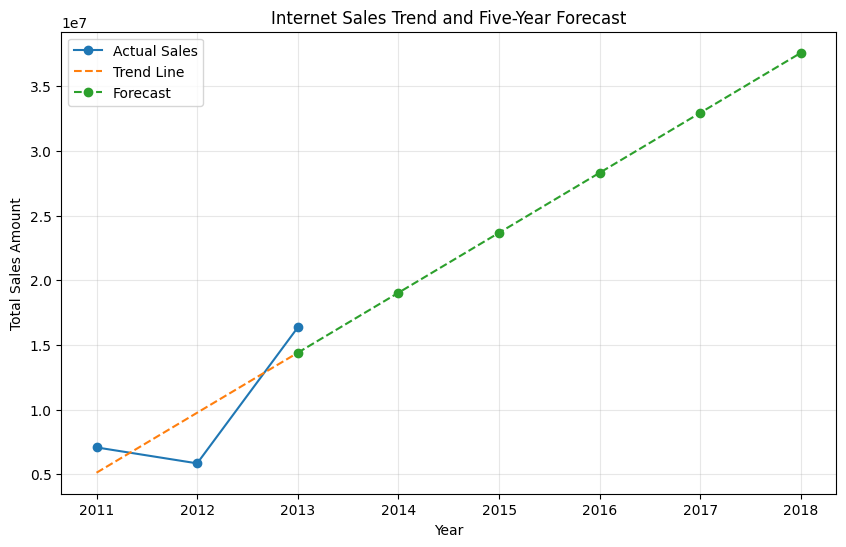

In [17]:
# plot trend line on the sales
plt.figure(figsize=(10, 6))

plt.plot(years, sales1, marker='o', label='Actual Sales') # historical sales
trend = slope * years + intercept
plt.plot(years, trend, '--', label='Trend Line') # linear trend line

# solve the disconnect issue from 2013 to 2014
forecast_years = np.insert(next_5years, 0, 2013)
forecast_values = np.insert(forecast_sales, 0, trend[-1])

plt.plot(forecast_years, forecast_values,
         marker='o', linestyle='--', label='Forecast')

plt.xlabel('Year')
plt.ylabel('Total Sales Amount')
plt.title('Internet Sales Trend and Five-Year Forecast')
plt.legend()
plt.grid(alpha=0.3)
plt.show()